# 06 · Temporal splits, floors and users

**Paper:** Section IV-D (*Temporal splits*), the user concentration in IV-F, the 21.6 % chance in
IV-G, and the corresponding *Limitations*.

Random splits mix jobs that are close in time, and jobs of the same user, on both sides. Here
every model trains on the past and is tested on the future (P9, code in [`tcc/splits.py`](../tcc/splits.py)):

* **main split:** jobs ordered by end time; the first 80 % train, the last 20 % test;
* **three blocks:** consecutive, each with about one third of the target-(a) positives, each with
  its own 80/20 split.

The splits are made on all five states together, so both targets cover the same periods; each
target then uses only its own states. They are made separately in the three populations.

Output: `data/splits_<population>.json` (job ids of every train and test set).

In [1]:
import sys
sys.path.insert(0, "..")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tcc.config import DATA, FLOOR, SEED
from tcc.claims import claim, save_claims
from tcc.splits import temporal_splits

F = pd.read_parquet(DATA / "features.parquet",
                    columns=["job_id", "user_id", "end_time", "job_state", "target_a", "target_b", "qos",
                             "complete", "complete_strict"])
populations = {"complete": F[F.complete == 1], "cohort": F, "strict": F[F.complete_strict == 1]}

## Make the splits and check them

In [2]:
splits, rows = {}, []
for pop, P in populations.items():
    sp = temporal_splits(P)
    Pi = P.set_index("job_id")
    for name, d in sp.items():
        train, test = Pi.loc[d["train"]], Pi.loc[d["test"]]
        assert train.end_time.max() < test.end_time.min(), f"{pop}/{name}: train is not before test"
        for role, s in (("train", train), ("test", test)):
            rows.append({"population": pop, "split": name, "role": role, "jobs": len(s),
                         "pos_a": int((s.target_a == 1).sum()), "prev_a": s.target_a.mean(),
                         "pos_b": int((s.target_b == 1).sum()), "prev_b": s.target_b.mean(),
                         "users": s.user_id.nunique(),
                         "users_with_failure_a": s.loc[s.target_a == 1, "user_id"].nunique(),
                         "from": s.end_time.min(), "to": s.end_time.max()})
    ends = [Pi.loc[np.r_[sp[f"block{k}"]["train"], sp[f"block{k}"]["test"]]].end_time for k in (1, 2, 3)]
    assert ends[0].max() < ends[1].min() and ends[1].max() < ends[2].min(), "blocks are not consecutive"
    assert sum(len(sp[f"block{k}"]["train"]) + len(sp[f"block{k}"]["test"]) for k in (1, 2, 3)) == len(P)
    splits[pop] = sp
    (DATA / f"splits_{pop}.json").write_text(json.dumps({n: {r: [int(i) for i in ids] for r, ids in d.items()}
                                                         for n, d in sp.items()}))
summary = pd.DataFrame(rows)
summary[summary.population == "complete"].set_index(["split", "role"]).drop(columns="population")

jobs  pos_a    prev_a  pos_b    prev_b  users  \
split  role                                                    
main   train  19286   2556  0.154041   2693  0.160968    287   
       test    4821    608  0.137494    399  0.094707    119   
block1 train   6006    480  0.091726    773  0.139884    132   
       test    1502    575  0.409253     97  0.104639     78   
block2 train   7612    828  0.124755    975  0.143721    216   
       test    1903    227  0.172231    585  0.349045    120   
block3 train   5667    930  0.181712    549  0.115896    143   
       test    1417    124  0.095092    113  0.087394     64   

              users_with_failure_a                      from  \
split  role                                                    
main   train                   154 2020-05-06 09:58:40+00:00   
       test                     31 2020-10-01 06:20:19+00:00   
block1 train                    58 2020-05-06 09:58:40+00:00   
       test                     22 2020-06-01 12:33:23+00:00   
block2 train                    95 2020-06-05 22:34:01+00:00   
       test                     41 2020-09-10 15:26:10+00:00   
block3 train                    67 2020-09-24 10:13:54+00:00   
       test                     14 2020-10-05 18:52:31+00:00   

                                    to  
split  role                             
main   train 2020-10-01 06:13:23+00:00  
       test  2020-10-12 17:24:14+00:00  
block1 train 2020-06-01 12:32:45+00:00  
       test  2020-06-05 22:33:49+00:00  
block2 train 2020-09-10 15:24:29+00:00  
       test  2020-09-24 10:13:53+00:00  
block3 train 2020-10-05 18:52:24+00:00  
       test  2020-10-12 17:24:14+00:00

The complete subset in time: cumulative target-(a) positives by end time, with the block limits
(dashed) and the main train/test cut (solid).

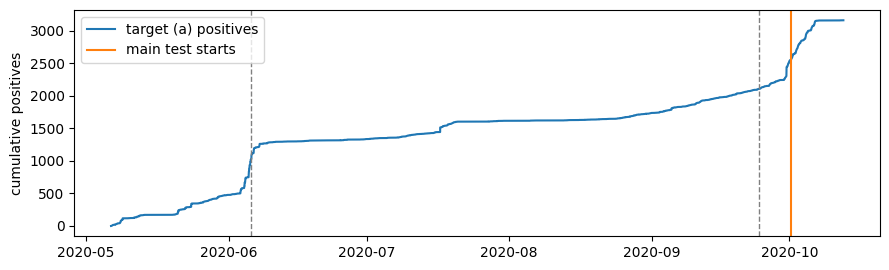

In [3]:
P = populations["complete"].sort_values(["end_time", "job_id"])
Pi = P.set_index("job_id")
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(P.end_time, np.cumsum(P.target_a == 1), color="C0", label="target (a) positives")
for k in (1, 2):
    ax.axvline(Pi.loc[splits["complete"][f"block{k}"]["test"]].end_time.max(), color="gray", ls="--", lw=1)
ax.axvline(Pi.loc[splits["complete"]["main"]["test"]].end_time.min(), color="C1", lw=1.5, label="main test starts")
ax.set_ylabel("cumulative positives")
ax.legend(loc="upper left")
plt.tight_layout()

## The main test set

In [4]:
main_test = summary.query("population == 'complete' and split == 'main' and role == 'test'").iloc[0]
main_train = summary.query("population == 'complete' and split == 'main' and role == 'train'").iloc[0]
print(f"main test: {main_test['from']} to {main_test['to']}")
claim("Main test: first day (October)", main_test["from"].day, "1")
claim("Main test: last day (October)", main_test["to"].day, "12")
claim("Main test: length in days", (main_test["to"].normalize() - main_test["from"].normalize()).days, "11")
claim("Main test: jobs (all five states)", main_test.jobs, "4,821")
claim("Main test: users with a target-(a) failure", main_test.users_with_failure_a, "31")
claim("Target-(a) prevalence, main training set", main_train.prev_a, "15.4%")
claim("Target-(a) prevalence, main test set", main_test.prev_a, "13.7%")

main test: 2020-10-01 06:20:19+00:00 to 2020-10-12 17:24:14+00:00
OK    Main test: first day (October): 1   (paper: 1)
OK    Main test: last day (October): 12   (paper: 12)
OK    Main test: length in days: 11   (paper: 11)
OK    Main test: jobs (all five states): 4821   (paper: 4,821)
OK    Main test: users with a target-(a) failure: 31   (paper: 31)
OK    Target-(a) prevalence, main training set: 15.4%   (paper: 15.4%)
OK    Target-(a) prevalence, main test set: 13.7%   (paper: 13.7%)


True

## Floors

Fixed before any model was fitted (P2): **100 positives** per test set, per target, and per
queue (qos 1 and qos 11) in the main test. A block below the floor makes the stability
condition B inconclusive; a queue below the floor waives condition C.

In [5]:
queue_rows = []
for pop, P in populations.items():
    Pi = P.set_index("job_id")
    test = Pi.loc[splits[pop]["main"]["test"]]
    for q in ("1", "11"):
        t = test[test.qos == q]
        queue_rows.append({"population": pop, "split": f"main, qos {q}", "role": "test", "jobs": len(t),
                     "pos_a": int((t.target_a == 1).sum()), "pos_b": int((t.target_b == 1).sum())})
tests = pd.concat([summary, pd.DataFrame(queue_rows)]).query("role == 'test'")
below = pd.concat([tests[tests[f"pos_{t}"] < FLOOR].assign(target=t)[["population", "split", "target", f"pos_{t}"]]
                   .rename(columns={f"pos_{t}": "positives"}) for t in "ab"])
below.sort_values(["population", "target"])

,population,split,target,positives
3,complete,block1,b,97
1,complete,"main, qos 11",b,98
21,strict,block2,a,84
23,strict,block3,a,75
4,strict,"main, qos 1",a,80
19,strict,block1,b,43
21,strict,block2,b,53
23,strict,block3,b,48
4,strict,"main, qos 1",b,33
5,strict,"main, qos 11",b,35


In [6]:
b = below[below.population == "complete"].set_index(["split", "target"]).positives
print(b)
assert len(b) == 2
claim("Below the floor: block-1 test, target (b)", b[("block1", "b")], "97")
claim("Below the floor: qos 11 in the main test, target (b)", b[("main, qos 11", "b")], "98")
blocks = summary[(summary.population == "complete") & summary.split.str.startswith("block")]
pos = blocks.groupby("split").pos_a.sum()
print("target-(a) positives per block (train + test):", pos.to_dict())

split         target
block1        b         97
main, qos 11  b         98
Name: positives, dtype: int64
OK    Below the floor: block-1 test, target (b): 97   (paper: 97)
OK    Below the floor: qos 11 in the main test, target (b): 98   (paper: 98)
target-(a) positives per block (train + test): {'block1': 1055, 'block2': 1055, 'block3': 1054}


In the strict population most block tests are below the floor (used in notebook 08):

In [7]:
tests[(tests.population == "strict") & tests.split.str.startswith("block")][["split", "pos_a", "pos_b"]]

,split,pos_a,pos_b
19,block1,264,43
21,block2,84,53
23,block3,75,48


## Failures cluster by user

Jobs of the same user are not independent, which is why notebook 08 resamples users, not jobs.

In [8]:
Pi = populations["complete"].set_index("job_id")
test = Pi.loc[splits["complete"]["main"]["test"]]
failures = test[test.target_a == 1].user_id.value_counts()
top10 = failures.head(10).sum() / failures.sum()
print(f"{len(failures)} users have a target-(a) failure in the main test; the ten largest hold {top10:.1%}")
claim("Ten largest users: share of target-(a) failures in the main test", top10, "94%")
claim("Ten largest users: share of target-(a) failures (Limitations)", top10, "94.4%")

31 users have a target-(a) failure in the main test; the ten largest hold 94.4%
OK    Ten largest users: share of target-(a) failures in the main test: 94%   (paper: 94%)
OK    Ten largest users: share of target-(a) failures (Limitations): 94.4%   (paper: 94.4%)


True

## A ranking can be right by chance

Condition B asks a group to be in the top three of at least two of the three blocks. If the ten
groups were ranked at random in each block, a given group is in the top three with probability
3/10 per block, so
P(≥ 2 of 3) = 3 · 0.3² · 0.7 + 0.3³.

In [9]:
p = 3 * 0.3**2 * 0.7 + 0.3**3
ranks = np.argsort(np.random.default_rng(SEED).random((100_000, 3, 10)), axis=2).argsort(axis=2)
simulated = ((ranks[:, :, 0] < 3).sum(axis=1) >= 2).mean()
print(f"exact {p:.4f}; simulated with 100,000 random rankings {simulated:.4f}")
claim("Chance of top 3 in >= 2 of 3 blocks", p, "21.6%")

exact 0.2160; simulated with 100,000 random rankings 0.2169
OK    Chance of top 3 in >= 2 of 3 blocks: 21.6%   (paper: 21.6%)


True

In [10]:
summary.to_csv(DATA / "splits_summary.csv", index=False)
save_claims("06_splits")

12 claims checked, 0 differ from the paper -> results/claims/06_splits.csv

,claim,computed,paper,ok,note
0,Main test: first day (October),1,1,True,
1,Main test: last day (October),12,12,True,
2,Main test: length in days,11,11,True,
3,Main test: jobs (all five states),4821,"4,821",True,
4,Main test: users with a target-(a) failure,31,31,True,
5,"Target-(a) prevalence, main training set",15.4%,15.4%,True,
6,"Target-(a) prevalence, main test set",13.7%,13.7%,True,
7,"Below the floor: block-1 test, target (b)",97,97,True,
8,"Below the floor: qos 11 in the main test, targ...",98,98,True,
9,Ten largest users: share of target-(a) failure...,94%,94%,True,
